In [2]:
# ==============================================================================
# Cell 1: Mount Google Drive & Import Libraries
# ==============================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Bidirectional, Dropout, BatchNormalization, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.utils import to_categorical
from tensorflow.keras import regularizers

# Local Windows environment — no Google Drive required
import os

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices("GPU"))
print("Working directory:", os.getcwd())
# Reproducibility seed
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPU Available: []
Working directory: C:\Users\GOKULNATH N\Downloads\ESP32_Secure_LSTM_Starter\ESP32_Secure_LSTM_Starter
TensorFlow Version: 2.21.0
GPU Available: []


In [3]:
# ==============================================================================
# Cell 2: Load and Prepare Dataset
# ==============================================================================

# Search for the CSV in Google Drive or specify your direct path:
# Common default location: '/content/drive/MyDrive/Autonomous_Pest_Detection_Dataset.csv'
DATASET_FILENAME = 'Autonomous_Pest_Detection_Dataset.csv'

file_path = None
for root, dirs, files in os.walk('/content/drive/MyDrive/'):
    if DATASET_FILENAME in files:
        file_path = os.path.join(root, DATASET_FILENAME)
        break

if file_path is None or not os.path.exists(file_path):
    # Fallback to local working directory if uploaded directly to Colab
    file_path = DATASET_FILENAME

print(f"Loading dataset from: {file_path}")
df = pd.read_csv(file_path)
print(f"Dataset shape: {df.shape}")
display(df.head())

# Define Feature Groups based on dataset schema
cat_cols = ['Crop_Type', 'Pest_Type', 'Weather_Condition', 'Soil_Type', 'Control_Action']
num_cols = [
    'Temperature_C', 'Humidity_Percentage', 'Soil_Moisture_Percentage',
    'Light_Intensity_Lux', 'CO2_Level_ppm', 'Wind_Speed_kmph',
    'Leaf_Damage_Percentage', 'Pest_Density', 'CNN_Feature_Score',
    'Detection_Confidence', 'Latency_ms', 'Pesticide_Usage_ml',
    'Battery_Level_Percentage', 'Network_Signal_Strength'
]
target_col = 'Target'

# Clean column names (strip whitespace or unexpected escape slashes)
df.columns = [c.replace('\\', '').strip() for c in df.columns]

# Drop missing values if any exist
df = df.dropna()

# Separate features and target
X = df[num_cols + cat_cols]
y = df[target_col]

# Encode Targets
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
num_classes = len(label_encoder.classes_)
y_categorical = to_categorical(y_encoded, num_classes=num_classes)

print("Target Classes:", label_encoder.classes_)

# Preprocessing Pipeline (StandardScaler for numericals, OneHotEncoder for categoricals)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

# Stratified Split: Train (70%), Validation (15%), Test (15%)
X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X, y_categorical, test_size=0.30, random_state=42, stratify=y_encoded
)

y_temp_indices = np.argmax(y_temp, axis=1)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.50, random_state=42, stratify=y_temp_indices
)

# Fit on training data ONLY to prevent data leakage
X_train_proc = preprocessor.fit_transform(X_train_raw)
X_val_proc = preprocessor.transform(X_val_raw)
X_test_proc = preprocessor.transform(X_test_raw)

# Reshape into 3D Tensors for LSTM: (samples, timesteps=1, features)
n_features = X_train_proc.shape[1]
X_train_lstm = X_train_proc.reshape((X_train_proc.shape[0], 1, n_features))
X_val_lstm = X_val_proc.reshape((X_val_proc.shape[0], 1, n_features))
X_test_lstm = X_test_proc.reshape((X_test_proc.shape[0], 1, n_features))

print(f"X_train shape: {X_train_lstm.shape}")
print(f"X_val shape:   {X_val_lstm.shape}")
print(f"X_test shape:  {X_test_lstm.shape}")

Loading dataset from: Autonomous_Pest_Detection_Dataset.csv
Dataset shape: (4000, 20)


,Crop_Type,Pest_Type,Weather_Condition,Soil_Type,Temperature_C,Humidity_Percentage,Soil_Moisture_Percentage,Light_Intensity_Lux,CO2_Level_ppm,Wind_Speed_kmph,Leaf_Damage_Percentage,Pest_Density,CNN_Feature_Score,Detection_Confidence,Latency_ms,Pesticide_Usage_ml,Battery_Level_Percentage,Network_Signal_Strength,Control_Action,Target
0,Wheat,Armyworm,Sunny,Silty,26.99,67.18,64.02,837.02,302.64,18.38,68.55,186.47,0.124,0.958,156.47,116.66,74.94,1.23,Irrigation_Adjustment,Moderate_Infestation
1,Wheat,Stem Borer,Humid,Sandy,40.82,82.35,61.55,234.03,300.20,5.02,46.76,65.52,0.107,0.975,56.46,177.52,53.01,4.79,Chemical_Spray,Low_Infestation
2,Potato,Leaf Miner,Dry,Silty,35.57,79.41,17.18,404.45,583.36,8.99,5.57,163.54,0.302,0.502,71.92,152.58,42.43,3.64,Biological_Control,Low_Infestation
3,Barley,Leaf Miner,Rainy,Clay,32.37,40.00,79.19,962.36,317.58,16.75,91.85,174.80,0.819,0.659,98.53,173.48,69.27,2.00,Biological_Control,Moderate_Infestation
4,Groundnut,Aphids,Dry,Sandy,21.74,39.70,52.64,705.12,884.72,12.31,98.03,86.28,0.914,0.919,109.79,11.88,79.22,3.13,Irrigation_Adjustment,Low_Infestation


Target Classes: ['Healthy_Crop' 'Low_Infestation' 'Moderate_Infestation'
 'Severe_Infestation']
X_train shape: (2800, 1, 46)
X_val shape:   (600, 1, 46)
X_test shape:  (600, 1, 46)


In [4]:
# ==============================================================================
# Cell 3: Bidirectional LSTM Model Architecture & Training
# ==============================================================================

def build_lstm_model(input_shape, num_classes):
    model = Sequential([
        Input(shape=input_shape),

        # Layer 1: Bidirectional LSTM with L2 regularization
        Bidirectional(LSTM(64, return_sequences=True, kernel_regularizer=regularizers.l2(1e-4))),
        BatchNormalization(),
        Dropout(0.3),

        # Layer 2: Core LSTM layer
        LSTM(32, return_sequences=False, kernel_regularizer=regularizers.l2(1e-4)),
        BatchNormalization(),
        Dropout(0.3),

        # Dense classification head
        Dense(32, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
        BatchNormalization(),
        Dropout(0.2),

        # Output probability distribution
        Dense(num_classes, activation='softmax')
    ])

    optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
    model.compile(
        optimizer=optimizer,
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

model = build_lstm_model((1, n_features), num_classes)
model.summary()

# Training Callbacks
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=12,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=1e-5,
        verbose=1
    )
]

# Train the model
history = model.fit(
    X_train_lstm, y_train,
    validation_data=(X_val_lstm, y_val),
    epochs=100,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)        │ (None, 1, 128)              │          56,832 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 1, 128)              │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1, 128)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 32)                  │          20,608 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 32)                  │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │           1,056 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 32)                  │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 4)                   │             132 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 79,396 (310.14 KB)

 Trainable params: 79,012 (308.64 KB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.4171 - loss: 1.4319 - val_accuracy: 0.2783 - val_loss: 1.2878 - learning_rate: 0.0010
Epoch 2/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5871 - loss: 0.9690 - val_accuracy: 0.4817 - val_loss: 1.1091 - learning_rate: 0.0010
Epoch 3/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6793 - loss: 0.7767 - val_accuracy: 0.6333 - val_loss: 0.8777 - learning_rate: 0.0010
Epoch 4/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7175 - loss: 0.6834 - val_accuracy: 0.7183 - val_loss: 0.6482 - learning_rate: 0.0010
Epoch 5/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7514 - loss: 0.6050 - val_accuracy: 0.8383 - val_loss: 0.4679 - learning_rate: 0.0010
Epoch 6/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7657 - loss: 0.5724 - val_accuracy: 0.8700 - val_loss: 0.4076 - learning_rate: 0.0010
Epoch 7/100
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7846 - loss: 0.5356 - val_ac


Test Accuracy: 90.00%
Test Loss:     0.2723

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Classification Report:
                      precision    recall  f1-score   support

        Healthy_Crop       0.93      0.92      0.92        97
     Low_Infestation       0.93      0.93      0.93       292
Moderate_Infestation       0.89      0.82      0.86       163
  Severe_Infestation       0.72      0.96      0.82        48

            accuracy                           0.90       600
           macro avg       0.87      0.91      0.88       600
        weighted avg       0.90      0.90      0.90       600



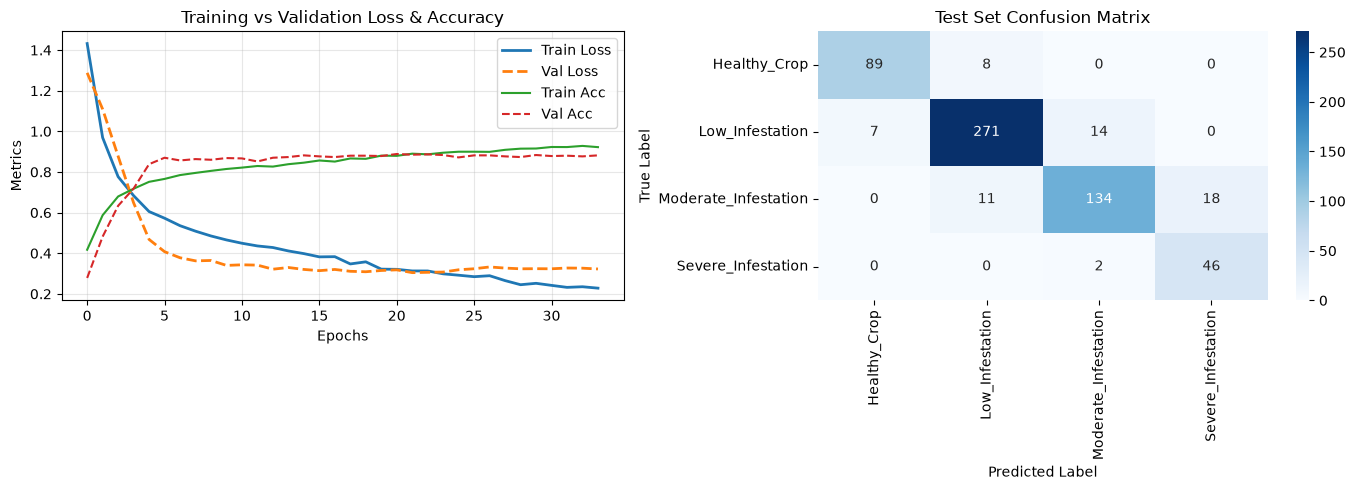

In [6]:
# ==============================================================================
# Cell 4: Rigorous Model Evaluation
# ==============================================================================

# Evaluate on Unseen Test Split
test_loss, test_accuracy = model.evaluate(X_test_lstm, y_test, verbose=0)
print(f"\n==========================================")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss:     {test_loss:.4f}")
print(f"==========================================\n")

# Predictions
y_pred_probs = model.predict(X_test_lstm)
y_pred_classes = np.argmax(y_pred_probs, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# Classification Report
print("Classification Report:")
print(classification_report(y_true_classes, y_pred_classes, target_names=label_encoder.classes_))

# Visualizations: Learning Curves & Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss & Accuracy Curves
axes[0].plot(history.history['loss'], label='Train Loss', color='#1f77b4', lw=2)
axes[0].plot(history.history['val_loss'], label='Val Loss', color='#ff7f0e', lw=2, linestyle='--')
axes[0].plot(history.history['accuracy'], label='Train Acc', color='#2ca02c', lw=1.5)
axes[0].plot(history.history['val_accuracy'], label='Val Acc', color='#d62728', lw=1.5, linestyle='--')
axes[0].set_title('Training vs Validation Loss & Accuracy')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Metrics')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Confusion Matrix Heatmap
cm = confusion_matrix(y_true_classes, y_pred_classes)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_,
            ax=axes[1])
axes[1].set_title('Test Set Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()

In [7]:
# ==============================================================================
# Cell 5: Interactive Crop Quality & Pest Diagnosis Console
# ==============================================================================

def get_valid_input(prompt, default, cast_type=float):
    val = input(f"{prompt} [Default: {default}]: ").strip()
    if not val:
        return cast_type(default)
    try:
        return cast_type(val)
    except ValueError:
        print(f"Invalid format. Falling back to default: {default}")
        return cast_type(default)

def run_interactive_diagnosis():
    print("\n" + "="*50)
    print("      SMART CROP & STORAGE QUALITY PREDICTOR")
    print("="*50)
    print("Provide sensor and ambient parameters (Press Enter for defaults):\n")

    # Crop & Environment
    crop = input("1. Crop Type (Rice/Wheat/Maize/Potato/Cotton/Barley/Sugarcane/Tomato/Soybean/Groundnut) [Default: Rice]: ").strip() or "Rice"
    weather = input("2. Weather Condition (Sunny/Rainy/Cloudy/Humid/Dry) [Default: Humid]: ").strip() or "Humid"
    soil = input("3. Soil Type (Clay/Loamy/Sandy/Silty) [Default: Clay]: ").strip() or "Clay"
    pest = input("4. Pest Observed (Aphids/Armyworm/Beetle/Leaf Miner/Mite/Stem Borer/Thrips/Whitefly) [Default: Beetle]: ").strip() or "Beetle"

    # Climate Telemetry
    temp = get_valid_input("5. Temperature (°C)", 28.5)
    humidity = get_valid_input("6. Relative Humidity (%)", 65.0)
    moisture = get_valid_input("7. Soil/Storage Moisture (%)", 45.0)
    light = get_valid_input("8. Light Intensity (Lux)", 550.0)

    # Gas Telemetry (MQ / CO2 Sensors)
    co2 = get_valid_input("9. CO2 / MQ Gas Sensor Level (ppm)", 480.0)
    wind = get_valid_input("10. Wind / Airflow Speed (km/h)", 12.0)

    # Visual / Sensor Diagnostics
    damage = get_valid_input("11. Visual Crop Damage (%)", 15.0)
    density = get_valid_input("12. Pest Density Count", 45.0)
    cnn_score = get_valid_input("13. Edge AI / CNN Feature Score (0.0 to 1.0)", 0.65)
    confidence = get_valid_input("14. Sensor Detection Confidence (0.0 to 1.0)", 0.85)

    # Operational metrics
    latency = get_valid_input("15. Sensor Latency (ms)", 180.0)
    pesticide = get_valid_input("16. Existing Chemical / Pesticide Volume (ml)", 50.0)
    battery = get_valid_input("17. IoT Node Battery (%)", 85.0)
    signal = get_valid_input("18. RSSI / Network Signal Strength (1.0 to 5.0)", 3.8)
    action = input("19. Active Intervention (No_Action/Trap_Deployment/Irrigation_Adjustment/Biological_Control/Chemical_Spray) [Default: No_Action]: ").strip() or "No_Action"

    # Assemble Input DataFrame
    input_dict = {
        'Crop_Type': [crop],
        'Pest_Type': [pest],
        'Weather_Condition': [weather],
        'Soil_Type': [soil],
        'Temperature_C': [temp],
        'Humidity_Percentage': [humidity],
        'Soil_Moisture_Percentage': [moisture],
        'Light_Intensity_Lux': [light],
        'CO2_Level_ppm': [co2],
        'Wind_Speed_kmph': [wind],
        'Leaf_Damage_Percentage': [damage],
        'Pest_Density': [density],
        'CNN_Feature_Score': [cnn_score],
        'Detection_Confidence': [confidence],
        'Latency_ms': [latency],
        'Pesticide_Usage_ml': [pesticide],
        'Battery_Level_Percentage': [battery],
        'Network_Signal_Strength': [signal],
        'Control_Action': [action]
    }

    input_df = pd.DataFrame(input_dict)

    # Transform using fitted preprocessor
    input_proc = preprocessor.transform(input_df)
    input_lstm = input_proc.reshape((1, 1, input_proc.shape[1]))

    # Predict
    probabilities = model.predict(input_lstm, verbose=0)[0]
    predicted_idx = np.argmax(probabilities)
    predicted_label = label_encoder.classes_[predicted_idx]
    confidence_score = probabilities[predicted_idx] * 100

    print("\n" + "="*50)
    print("               DIAGNOSIS REPORT")
    print("="*50)
    print(f"Target Crop:                {crop}")
    print(f"Predicted Crop Health:      {predicted_label.upper()}")
    print(f"Diagnostic Confidence:      {confidence_score:.2f}%\n")
    print("Class Probability Breakdown:")
    for cls, prob in zip(label_encoder.classes_, probabilities):
        bar = "█" * int(prob * 30)
        print(f" - {cls:<22}: {prob*100:5.2f}% | {bar}")

    print("\nOperational Prescriptive Guidance:")
    if predicted_label == "Healthy_Crop":
        print(" -> Optimal quality. Maintain regular aeration and baseline monitoring schedule.")
    elif predicted_label == "Low_Infestation":
        print(" -> Early stage risk detected. Deploy sticky/pheromone traps and optimize storage moisture.")
    elif predicted_label == "Moderate_Infestation":
        print(" -> Actionable threshold reached. Implement biological controls or adjust ventilation/irrigation.")
    else:
        print(" -> CRITICAL SEVERITY: Immediate targeted intervention or fumigation/isolation required.")
    print("="*50 + "\n")

# Run interactive loop
run_interactive_diagnosis()


      SMART CROP & STORAGE QUALITY PREDICTOR
Provide sensor and ambient parameters (Press Enter for defaults):



1. Crop Type (Rice/Wheat/Maize/Potato/Cotton/Barley/Sugarcane/Tomato/Soybean/Groundnut) [Default: Rice]:  rice
2. Weather Condition (Sunny/Rainy/Cloudy/Humid/Dry) [Default: Humid]:  Humid
3. Soil Type (Clay/Loamy/Sandy/Silty) [Default: Clay]:  Clay
4. Pest Observed (Aphids/Armyworm/Beetle/Leaf Miner/Mite/Stem Borer/Thrips/Whitefly) [Default: Beetle]:  Beetle
5. Temperature (°C) [Default: 28.5]:  28.5
6. Relative Humidity (%) [Default: 65.0]:  65.0
7. Soil/Storage Moisture (%) [Default: 45.0]:  60
8. Light Intensity (Lux) [Default: 550.0]:  400
9. CO2 / MQ Gas Sensor Level (ppm) [Default: 480.0]:  240
10. Wind / Airflow Speed (km/h) [Default: 12.0]:  10
11. Visual Crop Damage (%) [Default: 15.0]:  10
12. Pest Density Count [Default: 45.0]:  40
13. Edge AI / CNN Feature Score (0.0 to 1.0) [Default: 0.65]:  0.90
14. Sensor Detection Confidence (0.0 to 1.0) [Default: 0.85]:  0.9
15. Sensor Latency (ms) [Default: 180.0]:  180
16. Existing Chemical / Pesticide Volume (ml) [Default: 50.0]:  4


               DIAGNOSIS REPORT
Target Crop:                rice
Predicted Crop Health:      HEALTHY_CROP
Diagnostic Confidence:      55.62%

Class Probability Breakdown:
 - Healthy_Crop          : 55.62% | ████████████████
 - Low_Infestation       : 43.94% | █████████████
 - Moderate_Infestation  :  0.21% | 
 - Severe_Infestation    :  0.23% | 

Operational Prescriptive Guidance:
 -> Optimal quality. Maintain regular aeration and baseline monitoring schedule.



In [8]:
import os
import joblib

os.makedirs("models", exist_ok=True)

model.save("models/pest_lstm.keras")
joblib.dump(preprocessor, "models/preprocessor.joblib")
joblib.dump(label_encoder, "models/label_encoder.joblib")

print("Export completed:")
print(os.listdir("models"))

Export completed:
['.gitkeep', 'label_encoder.joblib', 'pest_lstm.keras', 'preprocessor.joblib']
